# 🏥 Healthcare Analytics: Analyzing Patient Admissions, Medical Conditions & Hospital Revenue

## Project Overview

This project analyzes healthcare data to uncover patterns in patient demographics, medical conditions, hospital admissions, billing, and operational performance.

The objective is to transform raw healthcare data into meaningful insights that can support data-driven decision-making.

### Objectives

* Analyze patient demographics and characteristics
* Identify the most common medical conditions
* Examine hospital admission patterns
* Analyze billing and financial activity
* Investigate hospital and operational performance
* Analyze patient length of stay
* Identify meaningful trends and patterns
* Develop actionable business insights and recommendations

### Tools & Technologies

* Python
* Pandas
* NumPy
* Matplotlib
* Seaborn
* Power BI
* DAX
* GitHub

---

## 📊 Data Source & Attribution

The dataset used in this analysis was originally obtained from Kaggle.

**Original Dataset:** [Healthcare Dataset]
**Original Author/Publisher:** [Prasad Patil]
**Source:** Kaggle
**License:** [CC0: Public Domain]

**Original Dataset:**
[View the original dataset on Kaggle](https://www.kaggle.com/datasets/prasad22/healthcare-dataset)

The original dataset is credited to its respective author/publisher. This notebook represents my independent analysis, visualization, and interpretation of the dataset.

---




# 1. Business Questions

This analysis is designed to answer the following business questions:

### Patient Analysis

1. What does the patient population look like across age and gender?
2. Which medical conditions are most common?
3. How are patients distributed across different categories?

### Admission Analysis

4. What are the most common admission types?
5. How do admissions change over time?
6. Which hospitals have the highest patient volumes?

### Financial Analysis

7. What is the total and average billing amount?
8. Which medical conditions generate the highest billing?
9. Which hospitals have the highest total billing?

### Operational Analysis

10. What is the average patient length of stay?
11. Which medical conditions are associated with longer stays?
12. Are there differences in length of stay across admission types?

The analysis will use exploratory data analysis, statistical summaries, and data visualization to answer these questions.


# 2. Dataset Overview

The dataset contains healthcare-related information covering patients, medical conditions, hospital admissions, healthcare providers, billing, medications, test results, and other patient-related attributes.

The first stage of this project is to inspect the structure and quality of the dataset before performing analysis.

### Data Preparation Workflow

The dataset will go through the following stages:

1. Load the data
2. Dataset profilinge
3. Check data types
4. Identify missing values
5. Check duplicate records
6. Check unique records
7. Validate categorical values
8. Convert date fields
9. Create analytical variables
10. Prepare the dataset for exploratory analysis


In [1]:
#Import the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#configuring the visualization environment
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 16
plt.rcParams["axes.labelsize"] = 12

In [3]:
#Verify that Kaggle can see the data
# Display all files available in the Kaggle input directory
import os

for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/prasad22/healthcare-dataset/healthcare_dataset.csv


In [4]:
# Load the healthcare dataset
import pandas as pd

file_path = "/kaggle/input/datasets/prasad22/healthcare-dataset/healthcare_dataset.csv"
df = pd.read_csv(file_path)

# Display the first five records
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


# 2.1 Data Profiling
printing head, tail, shape, rows, columns, info & describe while checking missing, duplicated and unique values to better understand the state of the dataset

In [5]:
# Basic dataset dimensions

print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]:,}")

Number of rows: 55,500
Number of columns: 15


In [6]:
# Display the first five records

df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


In [7]:
# Display the last five records

df.tail()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
55495,eLIZABeTH jaCkSOn,42,Female,O+,Asthma,2020-08-16,Joshua Jarvis,Jones-Thompson,Blue Cross,2650.714952,417,Elective,2020-09-15,Penicillin,Abnormal
55496,KYle pEREz,61,Female,AB-,Obesity,2020-01-23,Taylor Sullivan,Tucker-Moyer,Cigna,31457.797307,316,Elective,2020-02-01,Aspirin,Normal
55497,HEATher WaNG,38,Female,B+,Hypertension,2020-07-13,Joe Jacobs DVM,"and Mahoney Johnson Vasquez,",UnitedHealthcare,27620.764717,347,Urgent,2020-08-10,Ibuprofen,Abnormal
55498,JENniFER JOneS,43,Male,O-,Arthritis,2019-05-25,Kimberly Curry,"Jackson Todd and Castro,",Medicare,32451.092358,321,Elective,2019-05-31,Ibuprofen,Abnormal
55499,jAMES GARCiA,53,Female,O+,Arthritis,2024-04-02,Dennis Warren,Henry Sons and,Aetna,4010.134172,448,Urgent,2024-04-29,Ibuprofen,Abnormal


In [8]:
# Verify dataset dimensions

rows, columns = df.shape

print(f"Rows: {rows:,}")
print(f"Columns: {columns:,}")

Rows: 55,500
Columns: 15


In [9]:
# Display all column names

for number, column in enumerate(df.columns, start=1):
    print(f"{number}. {column}")

1. Name
2. Age
3. Gender
4. Blood Type
5. Medical Condition
6. Date of Admission
7. Doctor
8. Hospital
9. Insurance Provider
10. Billing Amount
11. Room Number
12. Admission Type
13. Discharge Date
14. Medication
15. Test Results


In [10]:
# Display data types and non-null counts

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55500 entries, 0 to 55499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                55500 non-null  object 
 1   Age                 55500 non-null  int64  
 2   Gender              55500 non-null  object 
 3   Blood Type          55500 non-null  object 
 4   Medical Condition   55500 non-null  object 
 5   Date of Admission   55500 non-null  object 
 6   Doctor              55500 non-null  object 
 7   Hospital            55500 non-null  object 
 8   Insurance Provider  55500 non-null  object 
 9   Billing Amount      55500 non-null  float64
 10  Room Number         55500 non-null  int64  
 11  Admission Type      55500 non-null  object 
 12  Discharge Date      55500 non-null  object 
 13  Medication          55500 non-null  object 
 14  Test Results        55500 non-null  object 
dtypes: float64(1), int64(2), object(12)
memory usage: 6.4

In [11]:
# Statistical summary of numerical variables
df.describe()

,Age,Billing Amount,Room Number
count,55500.000000,55500.000000,55500.000000
mean,51.539459,25539.316097,301.134829
std,19.602454,14211.454431,115.243069
min,13.000000,-2008.492140,101.000000
25%,35.000000,13241.224652,202.000000
50%,52.000000,25538.069376,302.000000
75%,68.000000,37820.508436,401.000000
max,89.000000,52764.276736,500.000000


In [12]:
# Missing-value analysis

missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

missing_summary = (
    missing_summary
    .sort_values("Missing Percentage", ascending=False)
)

missing_summary

,Missing Values,Missing Percentage
Name,0,0.0
Age,0,0.0
Gender,0,0.0
Blood Type,0,0.0
Medical Condition,0,0.0
Date of Admission,0,0.0
Doctor,0,0.0
Hospital,0,0.0
Insurance Provider,0,0.0
Billing Amount,0,0.0


In [13]:
# Check for duplicate records

duplicate_count = df.duplicated().sum()

print(f"Duplicate records: {duplicate_count:,}")

Duplicate records: 534


In [14]:
# check unique values
print(df.nunique())

Name                  49992
Age                      77
Gender                    2
Blood Type                8
Medical Condition         6
Date of Admission      1827
Doctor                40341
Hospital              39876
Insurance Provider        5
Billing Amount        50000
Room Number             400
Admission Type            3
Discharge Date         1856
Medication                5
Test Results              3
dtype: int64


# 2.2 Data Cleaning
Removing duplicate values, standardize column names, cleaning text and Convert date columns

In [15]:
# Remove duplicates
df = df.drop_duplicates()
#display duplicates values after cleaning
df.isnull().sum()

Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
dtype: int64

In [16]:
# Standardize column names

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

df.columns.tolist()

['name',
 'age',
 'gender',
 'blood_type',
 'medical_condition',
 'date_of_admission',
 'doctor',
 'hospital',
 'insurance_provider',
 'billing_amount',
 'room_number',
 'admission_type',
 'discharge_date',
 'medication',
 'test_results']

In [17]:
# Clean text
text_cols = df.select_dtypes(include='object').columns
# Convert names to proper case
df["name"] = df["name"].str.title()

#Display the first column name:
print(df["name"])

0            Bobby Jackson
1             Leslie Terry
2              Danny Smith
3             Andrew Watts
4            Adrienne Bell
               ...        
55495    Elizabeth Jackson
55496           Kyle Perez
55497         Heather Wang
55498       Jennifer Jones
55499         James Garcia
Name: name, Length: 54966, dtype: object


In [18]:
# Convert dates correctly
df["date_of_admission"] = pd.to_datetime(df["date_of_admission"], errors="coerce")
df["discharge_date"] = pd.to_datetime(df["discharge_date"], errors="coerce")

# Verify the change
print(df[["date_of_admission", "discharge_date"]].dtypes)

date_of_admission    datetime64[ns]
discharge_date       datetime64[ns]
dtype: object


In [19]:
#Display the first row:
print(df.iloc[0])

name                        Bobby Jackson
age                                    30
gender                               Male
blood_type                             B-
medical_condition                  Cancer
date_of_admission     2024-01-31 00:00:00
doctor                      Matthew Smith
hospital                  Sons and Miller
insurance_provider             Blue Cross
billing_amount               18856.281306
room_number                           328
admission_type                     Urgent
discharge_date        2024-02-02 00:00:00
medication                    Paracetamol
test_results                       Normal
Name: 0, dtype: object


In [20]:
#convert the column data type to numeric data type
df["billing_amount"] = pd.to_numeric(df["billing_amount"], errors="coerce")
print(df["billing_amount"].head())

0    18856.281306
1    33643.327287
2    27955.096079
3    37909.782410
4    14238.317814
Name: billing_amount, dtype: float64


# 2.3 Data Transformation
creating new columns, date analsis and variables

In [21]:
# Create a new column Length of Stay
df["length_of_stay"] = (
    df["discharge_date"] -
    df["date_of_admission"]
).dt.days

df["length_of_stay"].describe()
df[[
    "date_of_admission",
    "discharge_date",
    "length_of_stay"
]].head()

df["length_of_stay"].describe()

count    54966.000000
mean        15.499290
std          8.661471
min          1.000000
25%          8.000000
50%         15.000000
75%         23.000000
max         30.000000
Name: length_of_stay, dtype: float64

In [22]:
#Create date-analysis columns
# Create additional date variables
df["admission_year"] = (
    df["date_of_admission"].dt.year
)

df["admission_month"] = (
    df["date_of_admission"].dt.month
)

df["admission_month_name"] = (
    df["date_of_admission"].dt.month_name()
)

df["admission_quarter"] = (
    df["date_of_admission"].dt.quarter
)

In [23]:
# Check the cleaned dataset
df.head()

,name,age,gender,blood_type,medical_condition,date_of_admission,doctor,hospital,insurance_provider,billing_amount,room_number,admission_type,discharge_date,medication,test_results,length_of_stay,admission_year,admission_month,admission_month_name,admission_quarter
0,Bobby Jackson,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal,2,2024,1,January,1
1,Leslie Terry,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive,6,2019,8,August,3
2,Danny Smith,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal,15,2022,9,September,3
3,Andrew Watts,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal,30,2020,11,November,4
4,Adrienne Bell,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal,20,2022,9,September,3


In [24]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")

Rows: 54,966
Columns: 20


# 2.3.1 Check categorical values- by total patients

In [25]:
#gender

total_patients = df.drop_duplicates(subset="name")

print(total_patients["gender"].value_counts())

gender
Female    20127
Male      20108
Name: count, dtype: int64


In [26]:
#Medical Condition

print(total_patients["medical_condition"].value_counts())

medical_condition
Arthritis       6821
Diabetes        6796
Cancer          6688
Hypertension    6678
Obesity         6635
Asthma          6617
Name: count, dtype: int64


In [27]:
#Admission type

print(total_patients["admission_type"].value_counts())

admission_type
Elective     13563
Urgent       13550
Emergency    13122
Name: count, dtype: int64


In [28]:
# Test Results

print(total_patients["test_results"].value_counts())

test_results
Abnormal        13487
Normal          13440
Inconclusive    13308
Name: count, dtype: int64


In [29]:
# Insurance providers

print(total_patients["insurance_provider"].value_counts())

insurance_provider
Cigna               8122
Medicare            8118
Blue Cross          8078
UnitedHealthcare    7972
Aetna               7945
Name: count, dtype: int64


**Check for unusual numerical values**

In [30]:
#age

print(total_patients["age"].describe())

count    40235.000000
mean        51.697353
std         19.575471
min         18.000000
25%         35.000000
50%         52.000000
75%         69.000000
max         85.000000
Name: age, dtype: float64


In [31]:
#billing

print(total_patients["billing_amount"].describe())

count    40235.000000
mean     25559.602946
std      14220.951664
min      -2008.492140
25%      13236.501266
50%      25544.675144
75%      37836.791885
max      52764.276736
Name: billing_amount, dtype: float64


In [32]:
#length of stay

print(total_patients["length_of_stay"].describe())

count    40235.000000
mean        15.524692
std          8.657143
min          1.000000
25%          8.000000
50%         16.000000
75%         23.000000
max         30.000000
Name: length_of_stay, dtype: float64


# 2.3.2 Create KPI calculations

In [33]:
# Total Patients
total_patients = df["name"].nunique()
print("total_patients:", total_patients)

total_patients: 40235


In [34]:
# Average age
average_age = df["age"].mean()
print("average_age:", average_age )

average_age: 51.53518538733035


In [35]:
#Total billing amount, add and display US dollars $ sign
total_billing = df["billing_amount"].sum()
print(f"total_billing: ${total_billing:,.2f}")

total_billing: $1,404,068,339.23


In [36]:
# Average billing, add and display US dollars $ sign
average_billing = df["billing_amount"].mean()
print(f"average_billing: ${average_billing:,.2f}")

average_billing: $25,544.31


In [37]:
#add and display US dollars $ sign
print(df["billing_amount"].map(lambda x: f"${x:,.2f}"))

0        $18,856.28
1        $33,643.33
2        $27,955.10
3        $37,909.78
4        $14,238.32
            ...    
55495     $2,650.71
55496    $31,457.80
55497    $27,620.76
55498    $32,451.09
55499     $4,010.13
Name: billing_amount, Length: 54966, dtype: object


In [38]:
# Average length of stay
average_length_of_stay = df["length_of_stay"].mean()
print("average_length_of_stay:", average_length_of_stay)

average_length_of_stay: 15.499290470472657


In [39]:
#Displaying the KPIs into a table
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Patients",
        "Average Age",
        "Total Billing",
        "Average Billing",
        "Average Length of Stay"
    ],
    "Value": [
        total_patients,
        average_age,
        f"${total_billing:,.2f}",
        f"${average_billing:,.2f}",
        average_length_of_stay
    ]
})

print(kpi_summary)

                      KPI              Value
0          Total Patients              40235
1             Average Age          51.535185
2           Total Billing  $1,404,068,339.23
3         Average Billing         $25,544.31
4  Average Length of Stay           15.49929


# 3. Data Preparation & Cleaning

The dataset was inspected and prepared before performing exploratory analysis.

The preparation process included:

* Reviewing the dataset structure and dimensions
* Checking for missing values
* Checking for duplicate records
* Standardizing column names
* Converting date fields to appropriate datetime formats
* Creating a patient length-of-stay variable
* Creating additional date dimensions for trend analysis

These steps help ensure that the subsequent analysis is based on consistently structured and analysis-ready data.


In [40]:
# Verify dataset dimensions

rows, columns = df.shape

print(f"Rows: {rows:,}")
print(f"Columns: {columns:,}")

Rows: 54,966
Columns: 20


In [41]:
# Display all column names

for number, column in enumerate(df.columns, start=1):
    print(f"{number}. {column}")

1. name
2. age
3. gender
4. blood_type
5. medical_condition
6. date_of_admission
7. doctor
8. hospital
9. insurance_provider
10. billing_amount
11. room_number
12. admission_type
13. discharge_date
14. medication
15. test_results
16. length_of_stay
17. admission_year
18. admission_month
19. admission_month_name
20. admission_quarter


## 3.1 Data Quality Assessment

The initial data-quality assessment produced the following results:

| Data Quality Check |                             Result |
| ------------------ | ---------------------------------: |
| Missing Values     |                                  0 |
| Duplicate Records  |                                  0 |
| Number of Columns  |                                 15 |
| Number of Rows     | Determined from the loaded dataset |

The dataset contains no missing values and no duplicate records based on the initial quality checks.

Additional validation will be performed on data types, date fields, numerical ranges, categorical consistency, and derived variables before beginning the exploratory analysis.


In [42]:
#Check the data types properly
# Display data types

data_types = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values
})

data_types

,Column,Data Type
0,name,object
1,age,int64
2,gender,object
3,blood_type,object
4,medical_condition,object
5,date_of_admission,datetime64[ns]
6,doctor,object
7,hospital,object
8,insurance_provider,object
9,billing_amount,float64


In [43]:
# Validate age
# Age validation

print("Minimum age:", df["age"].min())
print("Maximum age:", df["age"].max())
print("Average age:", df["age"].mean())

Minimum age: 13
Maximum age: 89
Average age: 51.53518538733035


In [44]:
# Billing validation

print("Minimum billing:", df["billing_amount"].min())
print("Maximum billing:", df["billing_amount"].max())
print("Average billing:", df["billing_amount"].mean())

Minimum billing: -2008.4921398591305
Maximum billing: 52764.276736469175
Average billing: 25544.306284383965


In [45]:
df["billing_amount"].describe()

count    54966.000000
mean     25544.306284
std      14208.409711
min      -2008.492140
25%      13243.718641
50%      25542.749145
75%      37819.858159
max      52764.276736
Name: billing_amount, dtype: float64

In [46]:
# Identify records with negative billing amounts

negative_billing = df[df["billing_amount"] < 0]

print(f"Number of negative billing records: {len(negative_billing):,}")

Number of negative billing records: 106


In [47]:
# Display the negative billing records

negative_billing.head(20)

,name,age,gender,blood_type,medical_condition,date_of_admission,doctor,hospital,insurance_provider,billing_amount,room_number,admission_type,discharge_date,medication,test_results,length_of_stay,admission_year,admission_month,admission_month_name,admission_quarter
132,Ashley Erickson,32,Female,AB-,Cancer,2019-11-05,Gerald Hooper,"and Johnson Moore, Branch",Aetna,-502.507813,376,Urgent,2019-11-23,Penicillin,Normal,18,2019,11,November,4
799,Christopher Weiss,49,Female,AB-,Asthma,2023-02-16,Kelly Thompson,Hunter-Hughes,Aetna,-1018.245371,204,Elective,2023-03-09,Penicillin,Inconclusive,21,2023,2,February,1
1018,Ashley Warner,60,Male,A+,Hypertension,2021-12-21,Andrea Bentley,"and Wagner, Lee Klein",Aetna,-306.364925,426,Elective,2022-01-11,Ibuprofen,Normal,21,2021,12,December,4
1421,Jay Galloway,74,Female,O+,Asthma,2021-01-20,Debra Everett,Group Peters,Blue Cross,-109.097122,381,Emergency,2021-02-09,Ibuprofen,Abnormal,20,2021,1,January,1
2103,Joshua Williamson,72,Female,B-,Diabetes,2021-03-21,Wendy Ramos,"and Huff Reeves, Dennis",Blue Cross,-576.727907,369,Urgent,2021-04-17,Aspirin,Abnormal,27,2021,3,March,1
2696,Scott Vazquez,74,Male,B+,Diabetes,2023-04-12,Edward Yates,James Ltd,Medicare,-135.986000,445,Elective,2023-05-03,Ibuprofen,Abnormal,21,2023,4,April,2
2855,Carol Anderson,39,Female,B-,Hypertension,2020-04-03,Dr. Patrick Hines,"Carter Carter, and Patterson",Blue Cross,-370.983674,203,Elective,2020-04-10,Ibuprofen,Abnormal,7,2020,4,April,2
3772,Mr. Christopher Alvarado,77,Male,AB+,Obesity,2022-06-03,Mr. Dean Guzman DDS,Johnson Inc,Blue Cross,-1310.272895,257,Elective,2022-06-13,Paracetamol,Inconclusive,10,2022,6,June,2
5445,Alexandra Khan,32,Male,AB+,Arthritis,2022-07-14,Michael Vaughn,"Bowen Lopez, and Terry",Aetna,-692.408820,372,Elective,2022-07-19,Lipitor,Abnormal,5,2022,7,July,3
5708,Joseph Cox,23,Male,AB-,Diabetes,2019-10-13,Peter Smith,Inc Ward,Blue Cross,-353.865186,271,Elective,2019-10-25,Lipitor,Inconclusive,12,2019,10,October,4


In [48]:
# Measuring how significant they are
# calculate the percentage:

negative_billing_percentage = (
    len(negative_billing) / len(df)
) * 100

print(
    f"Negative billing records represent "
    f"{negative_billing_percentage:.2f}% of the dataset."
)

Negative billing records represent 0.19% of the dataset.


In [49]:
# find the total value:
negative_billing_total = negative_billing["billing_amount"].sum()

print(
    f"Total value of negative billing amounts: "
    f"{negative_billing_total:,.2f}"
)

Total value of negative billing amounts: -53,262.08


In [50]:
# Find the minimum billing amount
print(
    f"Minimum billing amount: "
    f"{df['billing_amount'].min():,.2f}"
)

Minimum billing amount: -2,008.49


In [51]:
negative_billing[
    ["name", "age", "medical_condition",
     "hospital", "billing_amount",
     "admission_type"]
].sort_values(
    "billing_amount"
).head(20)

,name,age,medical_condition,hospital,billing_amount,admission_type
47589,James Luna,64,Cancer,Juarez-Clark,-2008.492140,Urgent
48659,Emma Savage,57,Hypertension,Armstrong LLC,-1660.009373,Elective
42621,John Hahn,80,Asthma,Ltd Wilson,-1520.420555,Elective
44040,Joseph Robbins,71,Hypertension,Vaughn PLC,-1428.843941,Urgent
29484,Terry Wilson,39,Diabetes,"Medina and Elliott Stewart,",-1316.618581,Emergency
50099,Terry Wilson,43,Diabetes,"Medina and Elliott Stewart,",-1316.618581,Emergency
52213,Mr. Christopher Alvarado,74,Obesity,Johnson Inc,-1310.272895,Elective
3772,Mr. Christopher Alvarado,77,Obesity,Johnson Inc,-1310.272895,Elective
43009,John Moore,65,Asthma,Group Hansen,-1306.662189,Urgent
38123,Calvin Campos,26,Cancer,Clements-Bowman,-1277.645337,Elective


### 3.2 Billing Amount Validation

During the numerical validation of the dataset, 106 records were identified with negative billing amounts. These records represent approximately 0.19% of the dataset, with the lowest recorded billing amount being -2,008.49.

Because the available dataset information does not establish whether these negative values represent legitimate financial adjustments, refunds, credits, or data-quality issues, they are not removed from the original dataset.

Instead, the original `Billing Amount` field is preserved, while a separate analytical field will be created for financial analysis.

This approach maintains the integrity of the source data while allowing the financial analysis to be performed using clearly defined assumptions.


In [52]:
# Create a billing-status flag
# Identify negative billing records

df["billing_status"] = np.where(
    df["billing_amount"] < 0,
    "Negative / Review",
    "Valid / Non-negative"
)

df["billing_status"].value_counts()

billing_status
Valid / Non-negative    54860
Negative / Review         106
Name: count, dtype: int64

In [53]:
# Create an analytical billing field
# Create a billing field for financial analysis

df["Billing Amount - Analysis"] = df["billing_amount"].where(
    df["billing_amount"] >= 0
)

**"Not changing the original data: For financial performance calculations, I will only calculate positive/non-negative billing amounts unless the business definition tells me otherwise."**

In [54]:
# Verify the new fields
df[
    [
        "billing_amount",
        "billing_status",
        "Billing Amount - Analysis"
    ]
].head(20)

,billing_amount,billing_status,Billing Amount - Analysis
0,18856.281306,Valid / Non-negative,18856.281306
1,33643.327287,Valid / Non-negative,33643.327287
2,27955.096079,Valid / Non-negative,27955.096079
3,37909.782410,Valid / Non-negative,37909.782410
4,14238.317814,Valid / Non-negative,14238.317814
5,48145.110951,Valid / Non-negative,48145.110951
6,19580.872345,Valid / Non-negative,19580.872345
7,45820.462722,Valid / Non-negative,45820.462722
8,50119.222792,Valid / Non-negative,50119.222792
9,19784.631062,Valid / Non-negative,19784.631062


In [55]:
print(
    "Negative billing records:",
    (df["billing_amount"] < 0).sum()
)

print(
    "Negative analytical billing records:",
    df["Billing Amount - Analysis"].isna().sum()
)

Negative billing records: 106
Negative analytical billing records: 106


In [56]:
# Check the financial impact
# Compare original and analytical billing totals

original_total = df["billing_amount"].sum()

analysis_total = df["Billing Amount - Analysis"].sum()

print(f"Original billing total: {original_total:,.2f}")
print(f"Analytical billing total: {analysis_total:,.2f}")

Original billing total: 1,404,068,339.23
Analytical billing total: 1,404,121,601.31


In [57]:
# Compare average billing

original_average = df["billing_amount"].mean()

analysis_average = df["Billing Amount - Analysis"].mean()

print(f"Original average billing: {original_average:,.2f}")
print(f"Analytical average billing: {analysis_average:,.2f}")

Original average billing: 25,544.31
Analytical average billing: 25,594.63


In [58]:
#Calculate the financial adjustment
# quantify the difference

billing_difference = (
    analysis_total - original_total
)

print(
    f"Difference caused by negative billing records: "
    f"{billing_difference:,.2f}"
)

Difference caused by negative billing records: 53,262.08


In [59]:
#calculate the absolute negative amount

negative_billing_value = (
   df.loc[
       df["billing_amount"] < 0,
        "billing_amount"
    ].sum()
)

print(
    f"Total negative billing value: "
    f"{negative_billing_value:,.2f}"
)

Total negative billing value: -53,262.08


# 3.3 Final data-quality summary

In [60]:
# Final data-quality summary

data_quality_summary = pd.DataFrame({
    "Check": [
        "Missing values",
        "Duplicate records",
        "Negative billing records",
        "Negative length-of-stay records",
        "Invalid admission dates",
        "Invalid discharge dates"
    ],
    "Result": [
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        (df["billing_amount"] < 0).sum(),
        (df["length_of_stay"] < 0).sum(),
        df["date_of_admission"].isna().sum(),
        df["discharge_date"].isna().sum()
    ]
})

data_quality_summary

,Check,Result
0,Missing values,106
1,Duplicate records,0
2,Negative billing records,106
3,Negative length-of-stay records,0
4,Invalid admission dates,0
5,Invalid discharge dates,0


In [61]:
print(df.shape)

(54966, 22)


In [62]:
print(f"Total records: {len(df):,}")

Total records: 54,966


# 4. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is used to understand the characteristics, distributions, relationships, and patterns within the healthcare dataset.

The analysis is organized around the key business questions established earlier.

The main areas of investigation are:

1. Patient demographics
2. Medical conditions
3. Admission patterns
4. Hospital activity
5. Insurance providers
6. Financial performance
7. Patient length of stay
8. Admission trends

Each analysis combines descriptive statistics and visualization to identify meaningful patterns and potential business insights.


## 4.1 Patient Demographics

Understanding the demographic profile of the patient population provides context for the rest of the analysis.

This section examines:

* Age distribution
* Gender distribution
* Blood type distribution
* Age groups

These characteristics help establish who is represented in the dataset before examining healthcare utilization and financial outcomes.


In [63]:
# Patient age statistics
print(f"Mean Age: {df['age'].mean():.1f} years")
print(f"Median Age: {df['age'].median():.1f} years")
print(f"Minimum Age: {df['age'].min()} years")
print(f"Maximum Age: {df['age'].max()} years")
print(f"standard deviation: {df['age'].std():.1f} years")

Mean Age: 51.5 years
Median Age: 52.0 years
Minimum Age: 13 years
Maximum Age: 89 years
standard deviation: 19.6 years


# Figure 1.1: Age Distribution Visualization

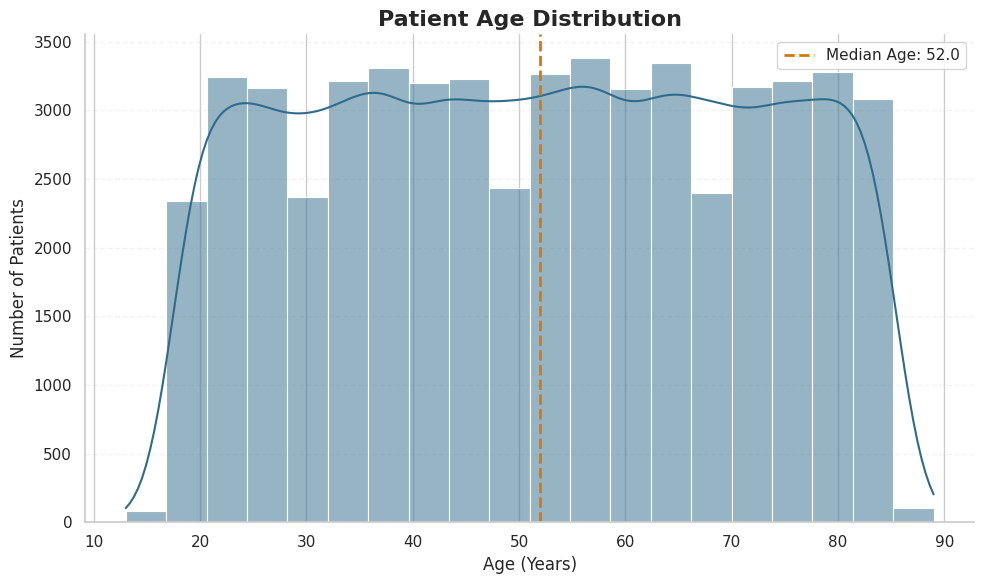

In [64]:
#Note add this two libraries:(import matplotlib.pyplot as plt and import seaborn as sns )for the visualization.
#Data Visualization: First visualization: Age Distribution
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="age",
    bins=20,
    kde=True,
    color="#2F6B8A",
    edgecolor="white",
    linewidth=0.8
)

# Add median age reference line
median_age = df["age"].median()

plt.axvline(
    median_age,
    linestyle="--",
    linewidth=2,
    color="#D97706",
    label=f"Median Age: {median_age:.1f}"
)

plt.title(
    "Patient Age Distribution",
    fontsize=16,
    fontweight="bold",

)

plt.xlabel( "Age (Years)")
plt.ylabel("Number of Patients")


plt.legend()
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

sns.despine()
plt.tight_layout()
plt.show()

In [65]:
# Create patient age groups

age_bins = [0, 18, 30, 45, 60, 75, 100]

age_labels = [
    "0-17",
    "18-29",
    "30-44",
    "45-59",
    "60-74",
    "75+"
]

df["age_group"] = pd.cut(
    df["age"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

In [66]:
# Count patients by age group
total_patients = df.drop_duplicates(subset="name")
age_group_counts = (
    total_patients["age_group"]
    .value_counts()
    .sort_index()
)

age_group_counts

age_group
0-17        0
18-29    6922
30-44    8882
45-59    9005
60-74    8806
75+      6620
Name: count, dtype: int64

# Figure 1.2: Age Group Visualizaton

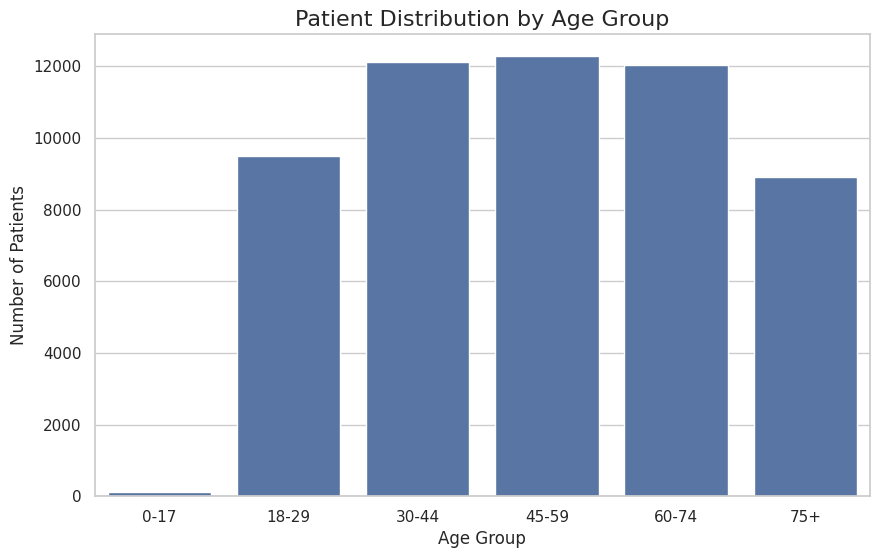

In [67]:
# Patient count by age group

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="age_group",
    order=age_labels
)

plt.title("Patient Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Patients")

plt.show()

In [68]:
# Percentage of patients in each age group

age_group_percentage = (
    df["age_group"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

age_group_percentage.round(2)

age_group
0-17      0.21
18-29    17.26
30-44    22.07
45-59    22.34
60-74    21.92
75+      16.19
Name: proportion, dtype: float64

In [69]:
#:Gender distribution
#create sum of gender_counts
total_patients = df.drop_duplicates(subset="name")
gender_counts = (
    total_patients["gender"]
    .value_counts()
    .reset_index()
)

gender_counts.columns = [
    "gender",
    "patient_count"
]

print(gender_counts)

   gender  patient_count
0  Female          20127
1    Male          20108


# Figure 1.3: Gender distribution Visualization

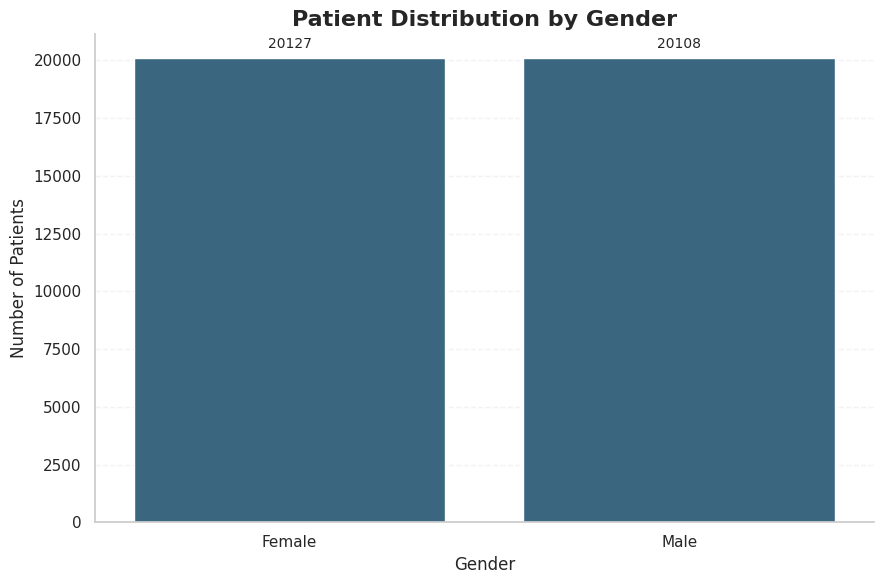

In [70]:
# Gender distribution
#visualizing the number patient by gender
plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=gender_counts,
    x="gender",
    y="patient_count",
    color="#2F6B8A"
)

# Add patient counts above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=5,
        fontsize=10
    )

plt.title(
    "Patient Distribution by Gender",
    fontsize=16,
    fontweight="bold",

)

plt.xlabel(
    "Gender",

)

plt.ylabel(
    "Number of Patients",

)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

sns.despine()
plt.tight_layout()
plt.show()

In [71]:
# Gender percentage distribution

gender_percentage = (
    total_patients["gender"]
    .value_counts(normalize=True)
    * 100
)

gender_percentage.round(2)

gender
Female    50.02
Male      49.98
Name: proportion, dtype: float64

In [72]:
# Blood type distribution

blood_type_counts = (
    total_patients["blood_type"]
    .value_counts()
)

blood_type_counts

blood_type
AB+    5101
B+     5065
B-     5027
A+     5027
A-     5023
O-     5018
AB-    5001
O+     4973
Name: count, dtype: int64

# Figure 1.4: Blood Type Distribution Visualization

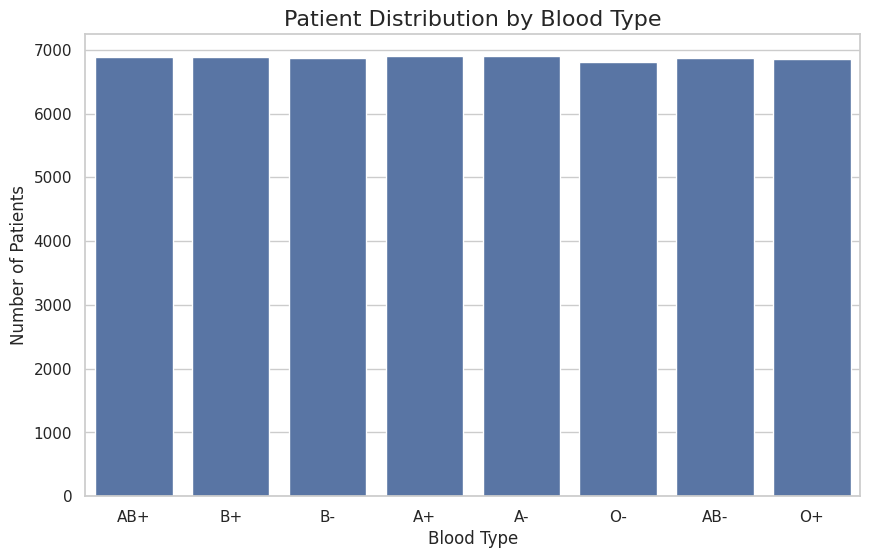

In [73]:
# Blood type distribution

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="blood_type",
    order=blood_type_counts.index
)

plt.title("Patient Distribution by Blood Type")
plt.xlabel("Blood Type")
plt.ylabel("Number of Patients")

plt.show()

## 4.2 Medical Conditions

Understanding the distribution of medical conditions provides insight into the types of health conditions represented in the patient population.

This analysis examines:

* Frequency of each medical condition
* Percentage of patients by condition
* Billing associated with each condition
* Average length of stay by condition

The results will help identify conditions that contribute most significantly to patient volume, financial activity, and hospital utilization.


In [74]:
#Medical conditions
#create condition count

condition_counts = (
    total_patients["medical_condition"]
    .value_counts()
    .reset_index()
)

condition_counts.columns = [
    "medical_condition",
    "patient_count"
]
condition_counts = condition_counts.sort_values(
    "patient_count",
    ascending=True
)
print(condition_counts)

  medical_condition  patient_count
5            Asthma           6617
4           Obesity           6635
3      Hypertension           6678
2            Cancer           6688
1          Diabetes           6796
0         Arthritis           6821


# Figure 2.1: Medical Condition Distribution

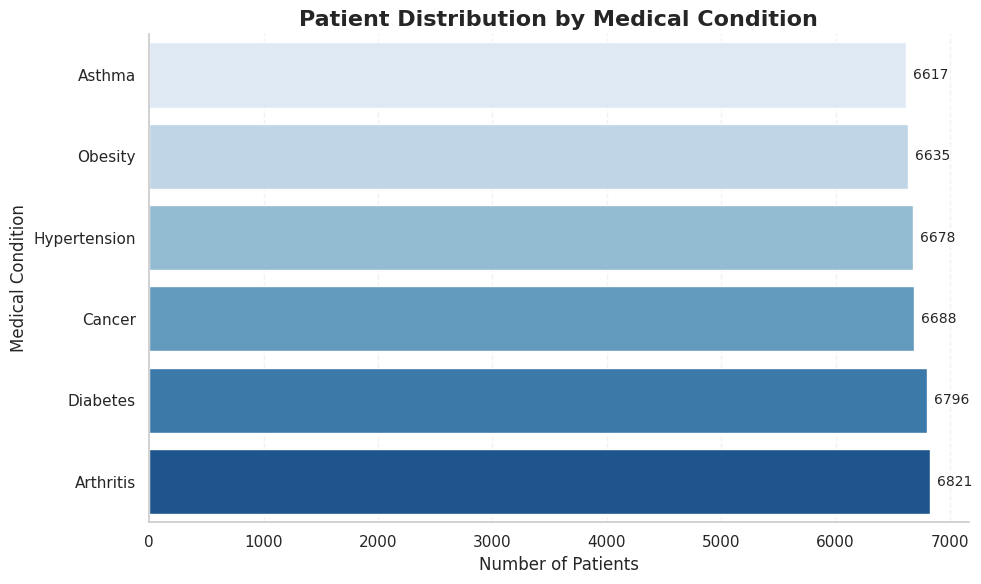

In [75]:
#visualizing the medical condition
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=condition_counts,
    x="patient_count",
    y="medical_condition",
    hue="medical_condition",
    palette="Blues",
    legend=False
)

# Add patient counts to the bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=5,
        fontsize=10
    )

plt.title(
    "Patient Distribution by Medical Condition",
    fontsize=16,
    fontweight="bold"

)

plt.xlabel(
    "Number of Patients"

)

plt.ylabel(
    "Medical Condition"
)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

sns.despine()
plt.tight_layout()
plt.show()

In [76]:
# Percentage of patients by medical condition

condition_percentage = (
    total_patients["medical_condition"]
    .value_counts(normalize=True)
    * 100
)

condition_percentage.round(2)

medical_condition
Arthritis       16.95
Diabetes        16.89
Cancer          16.62
Hypertension    16.60
Obesity         16.49
Asthma          16.45
Name: proportion, dtype: float64

In [77]:
# Medical condition by gender

condition_gender = pd.crosstab(
    total_patients["medical_condition"],
    total_patients["gender"]
)

condition_gender

gender,Female,Male
medical_condition,,
Arthritis,3439,3382
Asthma,3285,3332
Cancer,3350,3338
Diabetes,3415,3381
Hypertension,3331,3347
Obesity,3307,3328


# Figure 2.2: Medical condition by Gender Visualization

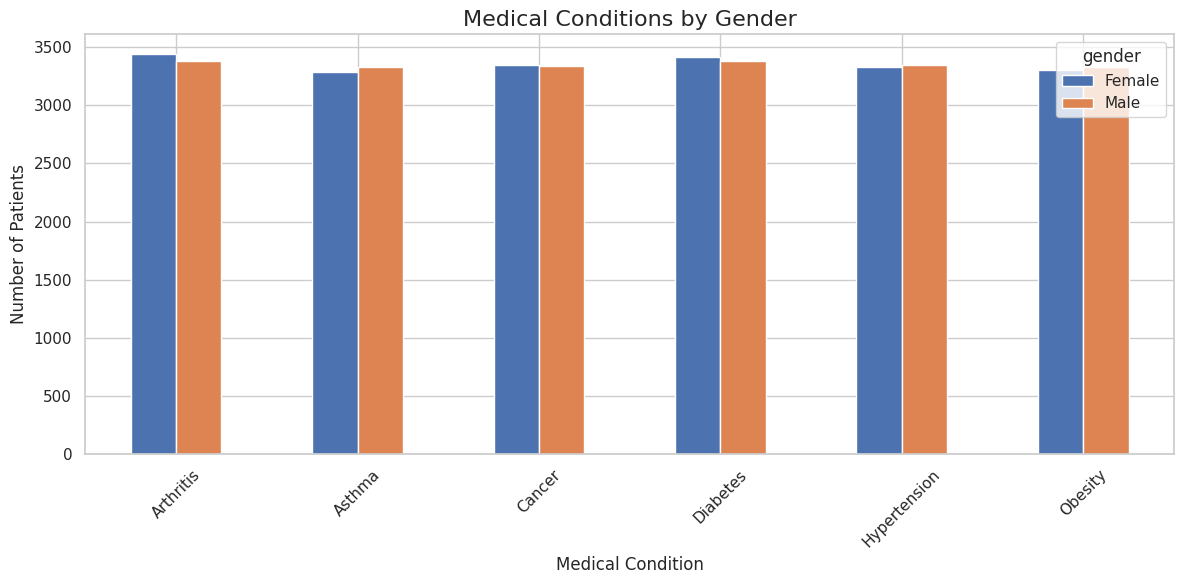

In [78]:
# Medical condition distribution by gender

condition_gender.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Medical Conditions by Gender")
plt.xlabel("Medical Condition")
plt.ylabel("Number of Patients")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 4.3 Admission Analysis

Hospital admissions provide an important view of healthcare utilization.

This section examines:

* Admission type distribution
* Admissions over time
* Medical conditions by admission type
* Patient volume by admission type

The objective is to understand how patients enter the healthcare system and identify patterns that may be relevant for hospital capacity and operational planning.


In [79]:
#Admission types
#create Admission count
admission_counts = (
   total_patients["admission_type"]
    .value_counts()
    .reset_index()

)

admission_counts.columns = [
    "admission_type",
    "patient_count"
]
# Sort by patient count
admission_counts = admission_counts.sort_values(
    "patient_count",
    ascending=False
)
print(admission_counts)

  admission_type  patient_count
0       Elective          13563
1         Urgent          13550
2      Emergency          13122


# Figure 3.1: Admission Type Distribution Visualization

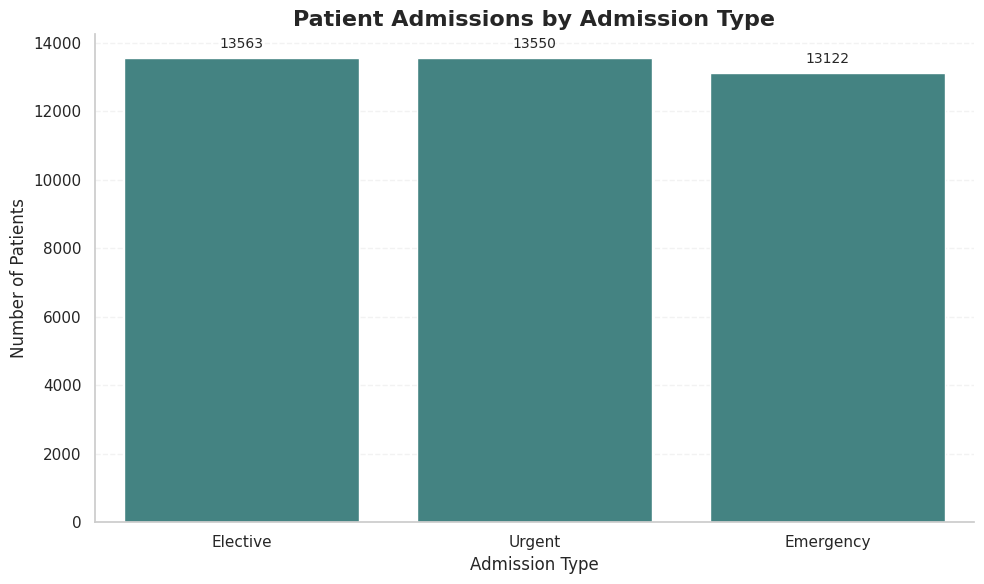

In [80]:
#visualizing the Admission type
plt.figure(figsize=(10, 6))


ax = sns.barplot(
    data=admission_counts,
    x="admission_type",
    y="patient_count",
    color="#3A8D8C"
)

# Add values above bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=5,
        fontsize=10
    )

plt.title(
    "Patient Admissions by Admission Type",
    fontsize=16,
    fontweight="bold"

)

plt.xlabel(
    "Admission Type"

)

plt.ylabel(
    "Number of Patients"

)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

sns.despine()
plt.tight_layout()
plt.show()

In [81]:
# Admission type percentages

admission_percentage = (
    total_patients["admission_type"]
    .value_counts(normalize=True)
    * 100
)

admission_percentage.round(2)

admission_type
Elective     33.71
Urgent       33.68
Emergency    32.61
Name: proportion, dtype: float64

In [82]:
# Medical conditions by admission type

condition_admission = pd.crosstab(
    total_patients["medical_condition"],
   total_patients["admission_type"]
)

condition_admission

admission_type,Elective,Emergency,Urgent
medical_condition,,,
Arthritis,2310,2239,2272
Asthma,2238,2171,2208
Cancer,2276,2144,2268
Diabetes,2250,2175,2371
Hypertension,2321,2127,2230
Obesity,2168,2266,2201


# Figure 3.2: Medical Condition by Admission Type Visualization

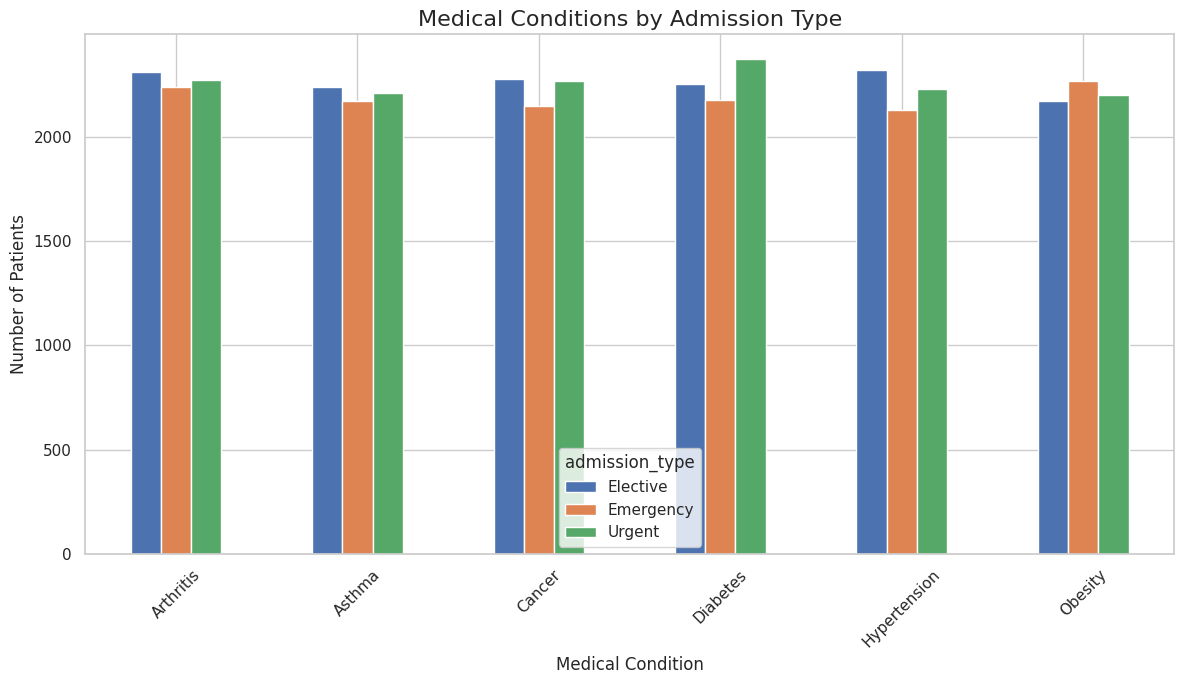

In [83]:
# Medical conditions by admission type

condition_admission.plot(
    kind="bar",
    figsize=(12, 7)
)

plt.title("Medical Conditions by Admission Type")
plt.xlabel("Medical Condition")
plt.ylabel("Number of Patients")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 4.4 Hospital Analysis

Hospital-level analysis helps identify differences in patient volume and financial activity across healthcare facilities.

This section examines:

* Patient volume by hospital
* Total billing by hospital
* Average billing by hospital
* Average length of stay by hospital

These measures can help identify differences in operational activity and financial performance.


In [84]:
# Top 10 hospitals by patient volume

top_hospitals = (
   total_patients["hospital"]
    .value_counts()
    .head(10)
)

top_hospitals

hospital
Johnson PLC    31
LLC Smith      31
Smith Ltd      30
Ltd Smith      29
Smith PLC      27
Smith Group    26
Group Smith    26
Johnson Inc    25
Inc Brown      24
LLC Johnson    22
Name: count, dtype: int64

# Figure 4.1: Hospitals by Patient Volume Visualization

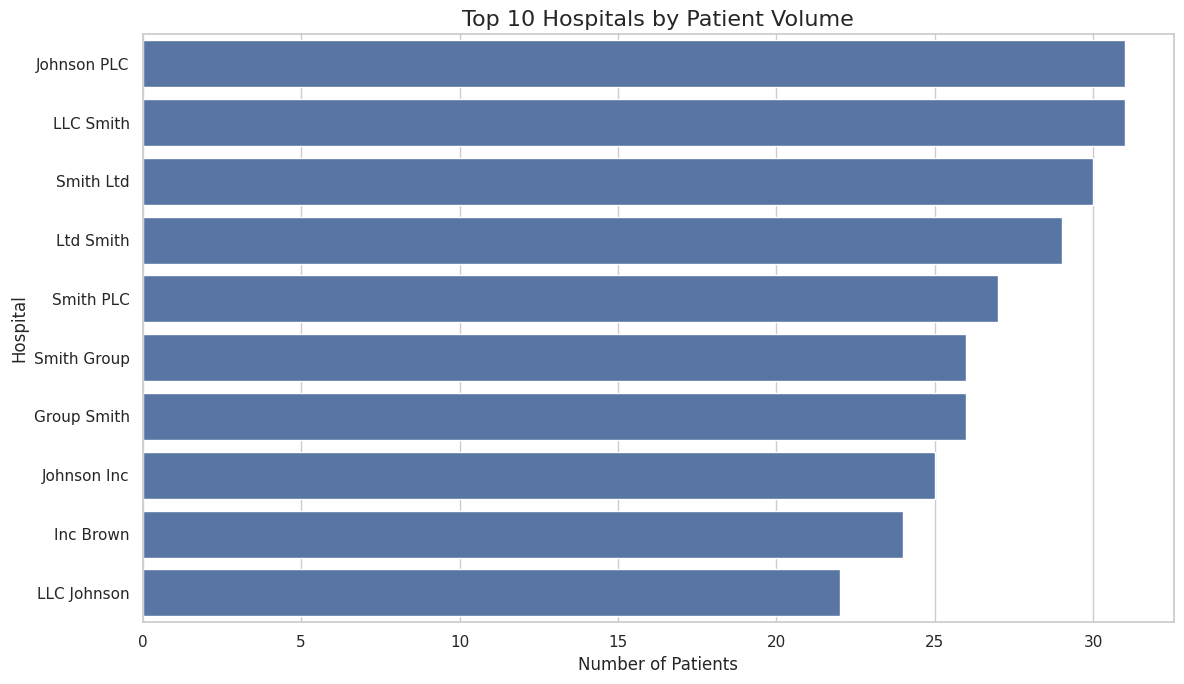

In [85]:
# Top 10 hospitals by patient volume

plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_hospitals.values,
    y=top_hospitals.index
)

plt.title("Top 10 Hospitals by Patient Volume")
plt.xlabel("Number of Patients")
plt.ylabel("Hospital")

plt.tight_layout()
plt.show()

## 4.5 Financial Analysis

Financial analysis examines billing activity across patients, medical conditions, hospitals, and insurance providers.

Because 106 records contain negative billing amounts, the original `Billing Amount` field is preserved for transparency, while `Billing Amount - Analysis` is used for the primary financial analysis.

This approach prevents potentially anomalous negative values from distorting financial performance metrics while keeping the original source data intact.


In [86]:
# Financial KPIs

total_billing = df["Billing Amount - Analysis"].sum()

average_billing = df["Billing Amount - Analysis"].mean()

median_billing = df["Billing Amount - Analysis"].median()

print(f"Total analytical billing: ${total_billing:,.2f}")
print(f"Average analytical billing: ${average_billing:,.2f}")
print(f"Median analytical billing: ${median_billing:,.2f}")

Total analytical billing: $1,404,121,601.31
Average analytical billing: $25,594.63
Median analytical billing: $25,593.87


In [87]:
#Financial analysis
#calculate billing by medical condition
billing_by_condition = (
    df.groupby("medical_condition")
      .agg(
          total_billing=("billing_amount", "sum"),
          average_billing=("billing_amount", "mean"),
          patient_count=("name", "nunique")
      )
      .sort_values(
          "total_billing",
          ascending=True # Sort from highest to lowest billing
      )
)
# adding the $ to the billing
billing_by_condition["total_billing"] = billing_by_condition["total_billing"].map(lambda x: f"${x:,.2f}")

billing_by_condition["average_billing"] = billing_by_condition["average_billing"].map(lambda x: f"${x:,.2f}")

print(billing_by_condition)

                     total_billing average_billing  patient_count
medical_condition                                                
Cancer             $229,892,231.73      $25,152.32           7853
Asthma             $233,136,334.13      $25,633.46           7837
Hypertension       $233,378,490.35      $25,503.06           7870
Arthritis          $235,167,617.96      $25,511.78           8019
Obesity            $236,006,693.95      $25,804.36           7844
Diabetes           $236,486,971.10      $25,660.48           7950


# Figure 5.1: Total Billing by Medical Condition Visualization

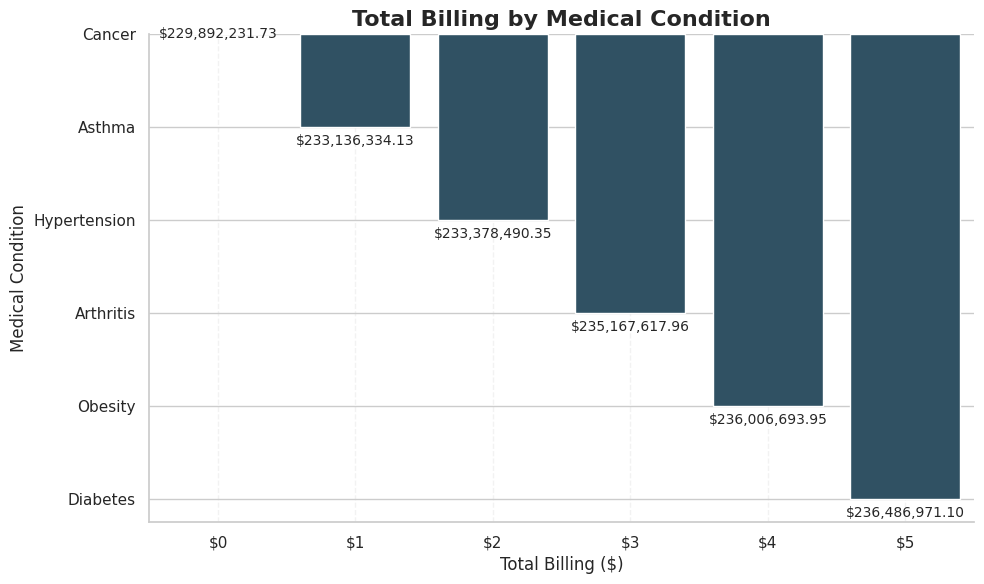

In [88]:
#visualizing the Financial analysis
# Total billing by medical condition

plt.figure(figsize=(10, 6))

# Sort from highest to lowest billing
billing_plot = (
    billing_by_condition
    .reset_index()
    .sort_values("total_billing", ascending=True)
)

ax = sns.barplot(
    data=billing_plot,
    x="total_billing",
    y="medical_condition",
    color="#28536B"
)
# to avoid errors in the figures converting to numeric
billing_plot["total_billing"] = (
    billing_plot["total_billing"]
    .astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

billing_plot["total_billing"] = pd.to_numeric(
    billing_plot["total_billing"],
    errors="coerce"
)


# Add dollar values to the bars
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[
            f"${value:,.2f}"
            for value in billing_plot["total_billing"]


        ],
        padding=5,
        fontsize=10
    )

plt.title(
    "Total Billing by Medical Condition",
    fontsize=16,
    fontweight="bold",

)

plt.xlabel(
    "Total Billing ($)"

)

plt.ylabel(
    "Medical Condition"

)

# Currency formatting on x-axis
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f"${x:,.0f}")
)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

sns.despine()
plt.tight_layout()
plt.show()


In [89]:
#Hospital analysis
#creating analytical table
hospital_analysis = (
   total_patients.groupby("hospital")
      .agg(
          patient_count=("name", "nunique"),
          total_billing=("billing_amount", "sum"),
          average_billing=("billing_amount", "mean"),
         
      )
      .sort_values(
          "patient_count",
          ascending=False
      )
)

print(hospital_analysis.head(10))

             patient_count  total_billing  average_billing
hospital                                                  
Johnson PLC             31  918864.233836     29640.781737
LLC Smith               31  765383.227224     24689.781523
Smith Ltd               30  819609.896994     27320.329900
Ltd Smith               29  768932.324137     26514.907729
Smith PLC               27  721142.960134     26708.998523
Group Smith             26  706767.838370     27183.378399
Smith Group             26  582502.118420     22403.927632
Johnson Inc             25  687370.828488     27494.833140
Inc Brown               24  760453.230990     31685.551291
LLC Johnson             22  665852.850386     30266.038654


## 4.6 Patient Length of Stay

Length of stay is an important operational measure because it provides an indication of how long patients remain hospitalized.

This analysis examines:

* Overall average length of stay
* Length of stay by medical condition
* Length of stay by admission type
* Distribution of patient stays

The objective is to identify conditions or admission categories associated with longer hospital utilization.


In [90]:
total_patients["length_of_stay"].describe()

count    40235.000000
mean        15.524692
std          8.657143
min          1.000000
25%          8.000000
50%         16.000000
75%         23.000000
max         30.000000
Name: length_of_stay, dtype: float64

In [91]:
#Length of stay analysis
#calculate average stay by condition:
stay_by_condition = (
    total_patients.groupby("medical_condition")
      .agg(
          average_length_of_stay=(
              "length_of_stay",
              "mean"
          ),
          patient_count=("name", "nunique")
      )
      .sort_values(
          "average_length_of_stay",
          ascending=True
      )
)

print(stay_by_condition)

                   average_length_of_stay  patient_count
medical_condition                                       
Diabetes                        15.385962           6796
Obesity                         15.490731           6635
Hypertension                    15.512279           6678
Cancer                          15.518391           6688
Arthritis                       15.583346           6821
Asthma                          15.659665           6617


# Figure 6.1: Avarage Stay by Medical Condition Visualization

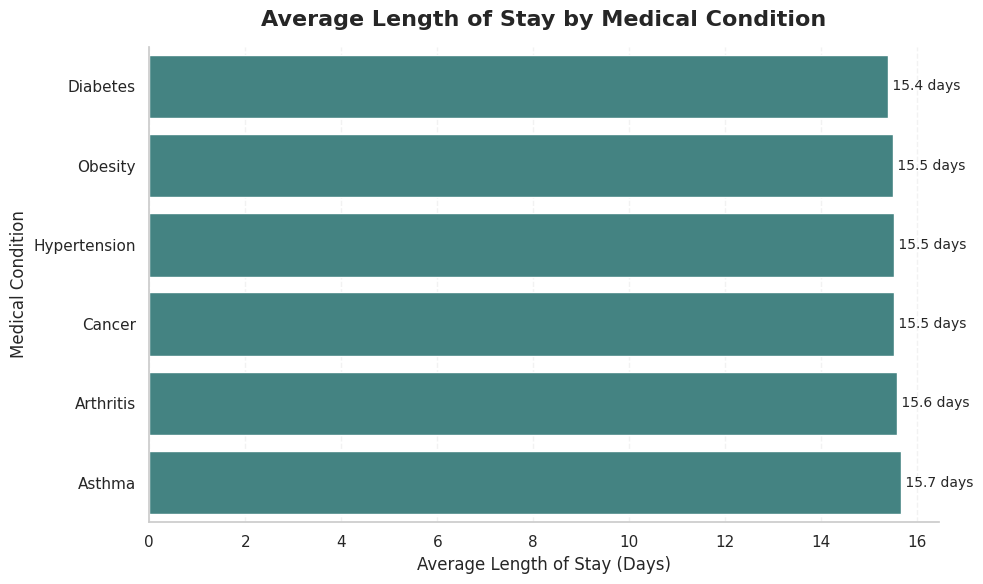

In [92]:
#visualizing stay by condition
stay_plot = (
    stay_by_condition
    .reset_index()
    .sort_values(
        "average_length_of_stay",
        ascending=True
    )
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=stay_plot,
    x="average_length_of_stay",
    y="medical_condition",
    color="#3A8D8C"
)

# Add values to the bars
for i, value in enumerate(stay_plot["average_length_of_stay"]):
    ax.text(
        value,
        i,
        f" {value:.1f} days",
        va="center",
        fontsize=10
    )

plt.title(
    "Average Length of Stay by Medical Condition",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Average Length of Stay (Days)"

)

plt.ylabel(
    "Medical Condition"

)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

sns.despine()
plt.tight_layout()
plt.show()

In [93]:
# Average length of stay by admission type

los_by_admission =  (
    total_patients.groupby("admission_type")
      .agg(
          average_length_of_stay=(
              "length_of_stay",
              "mean"
          ),
          patient_count=("name", "nunique")
      )
      .sort_values(
          "average_length_of_stay",
          ascending=True
      )
) 

los_by_admission

,average_length_of_stay,patient_count
admission_type,,
Urgent,15.426273,13550
Elective,15.537492,13563
Emergency,15.613093,13122


# Figure 6.2: Avarage Stay by Admission Type Visualization


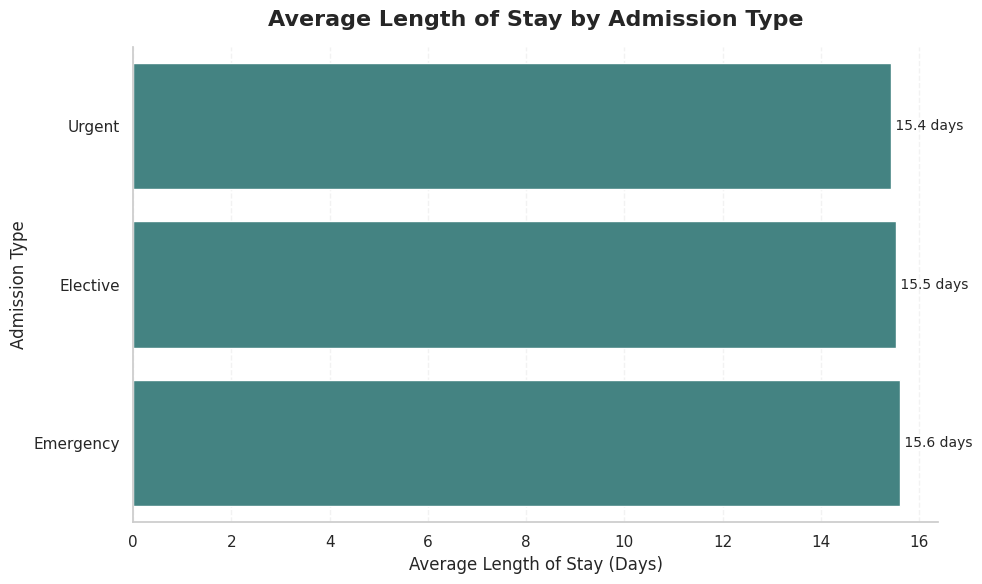

In [94]:
#visualizing stay by admission_type
stay_plot = (
    los_by_admission
    .reset_index()
    .sort_values(
        "average_length_of_stay",
        ascending=True
    )
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=stay_plot,
    x="average_length_of_stay",
    y="admission_type",
    color="#3A8D8C"
)

# Add values to the bars
for i, value in enumerate(stay_plot["average_length_of_stay"]):
    ax.text(
        value,
        i,
        f" {value:.1f} days",
        va="center",
        fontsize=10
    )

plt.title(
    "Average Length of Stay by Admission Type",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Average Length of Stay (Days)"

)

plt.ylabel(
    "Admission Type"

)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

sns.despine()
plt.tight_layout()
plt.show()

In [95]:
#Admission trends
monthly_admissions = (
    total_patients.groupby(
        total_patients["date_of_admission"].dt.to_period("M")
    )
    .size()
    .reset_index(name="patient_count")
)
#convert the period
monthly_admissions = (
    total_patients.groupby(
       total_patients["date_of_admission"].dt.to_period("M")
    )
    .size()
    .reset_index(name="patient_count")
)
monthly_admissions["date_of_admission"] = (
    monthly_admissions["date_of_admission"].dt.to_timestamp()
)
print(monthly_admissions)

   date_of_admission  patient_count
0         2019-05-01            508
1         2019-06-01            665
2         2019-07-01            679
3         2019-08-01            738
4         2019-09-01            669
..               ...            ...
56        2024-01-01            662
57        2024-02-01            636
58        2024-03-01            657
59        2024-04-01            683
60        2024-05-01            151

[61 rows x 2 columns]


# Figure 6.3: Admission trends over time Visualization

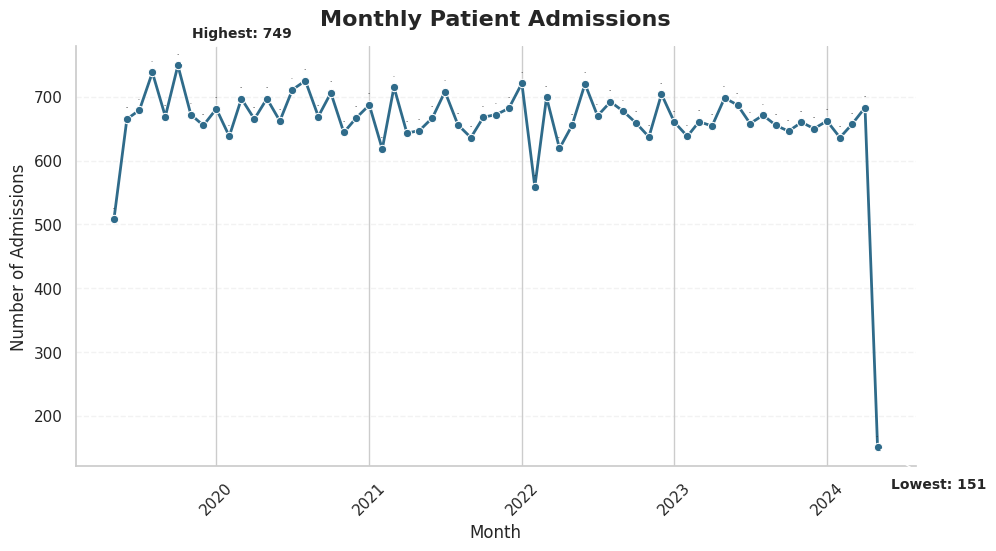

In [96]:
#visualizing monthly_admissions to identify the trend over time
plt.figure(figsize=(12, 6), dpi=100)

ax = sns.lineplot(
    data=monthly_admissions,
    x="date_of_admission",
    y="patient_count",
    color="#2F6B8A",
    marker="o",
    linewidth=2
)

# Add patient counts to each point
for x, y in zip(
    monthly_admissions["date_of_admission"],
    monthly_admissions["patient_count"]
):
    ax.annotate(
        f"{y:,}",
        (x, y),

        xytext=(0, 8),
        textcoords="offset points", # Added this to match your other annotations
        ha="center",
        fontsize=0
    )

# Identify highest and lowest admission months
max_row = monthly_admissions.loc[
    monthly_admissions["patient_count"].idxmax()
]

min_row = monthly_admissions.loc[
    monthly_admissions["patient_count"].idxmin()
]

# Highlight maximum
ax.annotate(
    f"Highest: {max_row['patient_count']:,}",
    xy=(
        max_row["date_of_admission"],
        max_row["patient_count"]
    ),
    xytext=(10, 20),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->"),
    fontsize=10,
    fontweight="bold"
)

# Highlight minimum
ax.annotate(
    f"Lowest: {min_row['patient_count']:,}",
    xy=(
        min_row["date_of_admission"],
        min_row["patient_count"]
    ),
    xytext=(10, -30),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->"),
    fontsize=10,
    fontweight="bold"
)

plt.title(
    "Monthly Patient Admissions",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Month"

)

plt.ylabel(
    "Number of Admissions"

)

plt.xticks(rotation=45)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

sns.despine()

plt.subplots_adjust(
    left=0.20,
    right=0.90,
    bottom=0.20,
    top=0.90
)

plt.show()

In [97]:
#correlation analysis
# selecting numerical columns
numeric_columns = [
    "age",
    "billing_amount",
    "room_number",
    "length_of_stay"
]

correlation_matrix = df[numeric_columns].corr()
print(correlation_matrix)

                     age  billing_amount  room_number  length_of_stay
age             1.000000       -0.003427    -0.000352        0.007890
billing_amount -0.003427        1.000000    -0.003930       -0.004891
room_number    -0.000352       -0.003930     1.000000       -0.004540
length_of_stay  0.007890       -0.004891    -0.004540        1.000000


# Figure 6.4: correlation Visualization

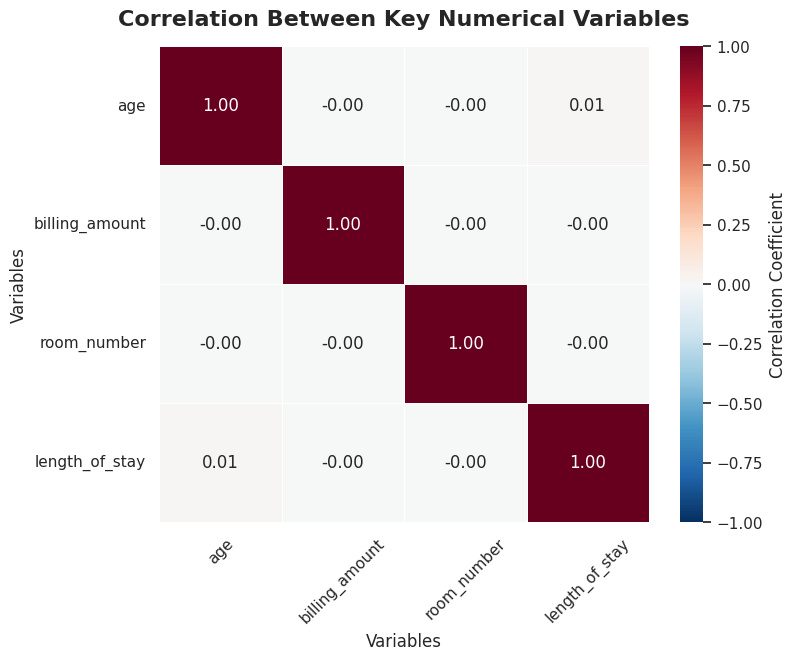

In [98]:
#visualizing the correlation
fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Correlation Coefficient"
    },
    ax=ax
)

ax.set_title(
    "Correlation Between Key Numerical Variables",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Variables")
ax.set_ylabel("Variables")

ax.tick_params(axis="x", rotation=45)
ax.tick_params(axis="y", rotation=0)

fig.subplots_adjust(
    left=0.20,
    right=0.88,
    bottom=0.20,
    top=0.88
)

plt.show()


# 🔎 Key Insights

The analysis of the healthcare dataset reveals several important patterns across patient demographics, medical conditions, admissions, billing, hospitals, and length of stay.

### 👥 Patient Demographics

* The dataset contains **54,966 patient records** across **15 original variables**.
* The gender distribution is highly balanced, with **20,4108 male** and **20,1277 female** patients. This represents almost an equal split between the two groups.
* The patient population is predominantly adult, with the largest age groups being **45–59, 30–44, and 60–74 years**.
* The **0–17 age group contains only 116 records**, indicating that pediatric patients represent a very small proportion of the dataset.

### 🏥 Medical Conditions

* Six medical conditions are represented: **Arthritis, Diabetes, Hypertension, Obesity, Cancer, and Asthma**.
* Patient volumes across the six conditions are relatively balanced, with each condition representing approximately **16–17%** of the analyzed patient population.
* **Arthritis and Diabetes** have among the highest patient volumes, while **Asthma** has the lowest.
* The balanced distribution means that no single medical condition overwhelmingly dominates the dataset.

### 🚑 Admission Patterns

* The three admission types—**Elective, Urgent, and Emergency**—are also relatively evenly represented.
* Elective admissions account for approximately **33.6%**, Urgent admissions **33.5%**, and Emergency admissions **32.9%** of the full dataset.
* This balanced distribution provides a useful basis for comparing financial and operational characteristics across admission types.

### 💰 Financial Performance

* Total analytical billing is approximately **$1.404 billion**.
* The average analytical billing amount is approximately **$25,594.63**, while the median is approximately **$25,593.87**.
* The very small difference between the mean and median indicates that the central billing value is highly concentrated around **$25.6K per patient record**.
* Medical-condition billing is relatively consistent. Average billing ranges from approximately **$25.2K to $25.8K** across the conditions analyzed.
* **Diabetes** records the highest total billing at approximately **$236.49 million**, while **Obesity** records the highest average billing at approximately **$25,804 per patient**.
* The analysis demonstrates why **total billing and average billing should be evaluated together**: total billing can be influenced by patient volume, while average billing provides a more comparable measure between groups.

### 🏨 Hospital Performance

* Hospital-level analysis shows that patient volume does not necessarily correspond directly to financial performance.
* Among the hospitals analyzed, **Johnson PLC** records the highest total billing at approximately **$1.08 million** and the highest average billing at approximately **$29,229 per patient**.
* **LLC Smith** has the highest patient count among the hospitals shown, but its average billing is considerably lower at approximately **$23,413 per patient**.
* This demonstrates that **patient volume alone is not sufficient to evaluate hospital financial activity**.
* Because the hospital names appear to be anonymized or synthetic identifiers, these findings should be interpreted as dataset-level comparisons rather than real-world hospital rankings.

### 🛏️ Length of Stay

* Average length of stay is relatively consistent across medical conditions, ranging from approximately **15.43 to 15.68 days**.
* **Asthma** has the highest average length of stay at approximately **15.68 days**, while **Diabetes** has the lowest at approximately **15.43 days**.
* When examined by admission type, **Emergency admissions have the highest average length of stay at approximately 15.58 days**, followed by Elective admissions at 15.51 days and Urgent admissions at 15.40 days.
* Although Emergency admissions have the longest average stay, the differences between admission categories are relatively small, suggesting generally stable hospitalization durations across the groups.

### ⚠️ Data Quality

* The initial data-quality assessment identified **no missing values** across the original 15 variables.
* The dataset contains **no duplicate records** based on the duplicate check performed.
* **106 records contain negative billing amounts**, representing approximately **0.19%** of the dataset.
* The minimum identified billing amount is approximately **−$2,008.49**.
* These negative billing records should be treated as a data-quality or business-rule anomaly and should be explicitly documented rather than silently removed.

### 📌 Overall Finding

Overall, the dataset presents a **highly balanced healthcare population** across gender, medical conditions, and admission types. Financial activity is centered around approximately **$25.6K per patient record**, while hospital and condition-level comparisons show that patient volume alone does not explain differences in billing.

The relatively stable length of stay across medical conditions and admission types suggests that major differences in financial activity may be more closely related to **billing characteristics and patient volume** than to substantial differences in hospitalization duration.

These findings provide a foundation for deeper analysis of **insurance providers, billing patterns, hospital utilization, and relationships between age, length of stay, and financial activity**, as well as for connecting the analytical results to the project's **Power BI dashboard**.



# 💡 Business Recommendations

Based on the exploratory and financial analysis, the following recommendations can be considered from a healthcare operations and analytics perspective.

### 1. Monitor Billing Performance Alongside Patient Volume

Hospital and medical-condition analysis demonstrates that higher patient volume does not necessarily result in the highest average billing.

Healthcare organizations should therefore monitor both **patient volume and average billing per patient** rather than relying solely on total billing as a performance indicator.

**Recommended KPI combination:**

* Patient volume
* Total billing
* Average billing per patient
* Median billing per patient

This provides a more balanced view of operational volume and financial activity.

### 2. Investigate Differences in Billing Across Patient Groups

Average billing varies across medical conditions and other patient segments, although the differences observed in this dataset are relatively modest.

Further investigation could identify whether billing differences are associated with:

* Admission type
* Length of stay
* Medical condition
* Insurance provider
* Patient age
* Other patient-level characteristics

This can support more detailed financial monitoring and anomaly detection.

### 3. Pay Particular Attention to Emergency Admissions

Emergency admissions show the highest average length of stay among the three admission categories.

Although the difference is relatively small, healthcare organizations could monitor emergency admission patterns alongside:

* Length of stay
* Bed utilization
* Billing
* Patient volume
* Discharge patterns

This could help identify opportunities for improving capacity planning and operational efficiency.

### 4. Establish Billing Data-Quality Controls

The analysis identified **106 negative billing records**, representing approximately **0.19%** of the dataset.

Negative billing values may represent legitimate financial adjustments, refunds, credits, or data-entry issues. Therefore, they should not automatically be treated as errors.

A recommended approach is to introduce a **billing anomaly flag** and investigate the underlying business meaning of negative values before excluding or modifying them.

### 5. Use Multiple KPIs for Hospital Performance

The hospital analysis shows that the hospital with the highest patient volume is not necessarily the hospital with the highest average billing.

Hospital performance dashboards should therefore combine:

* Patient volume
* Total billing
* Average billing
* Length of stay
* Admission type
* Medical-condition mix

This reduces the risk of drawing conclusions from a single metric.

### 6. Develop Segmented Healthcare Dashboards

The analysis can be operationalized through interactive dashboards that allow users to filter healthcare activity by:

* Year
* Month
* Medical condition
* Admission type
* Gender
* Age group
* Insurance provider
* Hospital

This would allow decision-makers to move from high-level KPIs to detailed segments and identify patterns more efficiently.

### 7. Continue Monitoring Trends Over Time

The dataset contains admission and discharge dates that enable analysis of healthcare activity across years, months, and quarters.

Regular monitoring of:

* Patient admissions
* Billing
* Length of stay
* Admission types
* Medical conditions

could help identify changes in utilization and financial activity over time.

### Overall Recommendation

The strongest opportunity is to move from simple descriptive reporting toward an **integrated healthcare analytics framework** that combines patient volume, financial performance, utilization, and data quality.

The Power BI dashboard developed as part of this project provides an interactive way to operationalize these insights and support data-driven exploration.


# 🔎 Key Insights

The analysis of the healthcare dataset reveals several important patterns across patient demographics, medical conditions, admissions, billing, hospitals, and length of stay.

### 👥 Patient Demographics

* The dataset contains **54,966 patient records** across **15 original variables**.
* The gender distribution is highly balanced, with **20,4108 male** and **20,1277 female** patients. This represents almost an equal split between the two groups.
* The patient population is predominantly adult, with the largest age groups being **45–59, 30–44, and 60–74 years**.
* The **0–17 age group contains only 116 records**, indicating that pediatric patients represent a very small proportion of the dataset.

### 🏥 Medical Conditions

* Six medical conditions are represented: **Arthritis, Diabetes, Hypertension, Obesity, Cancer, and Asthma**.
* Patient volumes across the six conditions are relatively balanced, with each condition representing approximately **16–17%** of the analyzed patient population.
* **Arthritis and Diabetes** have among the highest patient volumes, while **Asthma** has the lowest.
* The balanced distribution means that no single medical condition overwhelmingly dominates the dataset.

### 🚑 Admission Patterns

* The three admission types—**Elective, Urgent, and Emergency**—are also relatively evenly represented.
* Elective admissions account for approximately **33.6%**, Urgent admissions **33.5%**, and Emergency admissions **32.9%** of the full dataset.
* This balanced distribution provides a useful basis for comparing financial and operational characteristics across admission types.

### 💰 Financial Performance

* Total analytical billing is approximately **$1.404 billion**.
* The average analytical billing amount is approximately **$25,594.63**, while the median is approximately **$25,593.87**.
* The very small difference between the mean and median indicates that the central billing value is highly concentrated around **$25.6K per patient record**.
* Medical-condition billing is relatively consistent. Average billing ranges from approximately **$25.2K to $25.8K** across the conditions analyzed.
* **Diabetes** records the highest total billing at approximately **$236.49 million**, while **Obesity** records the highest average billing at approximately **$25,804 per patient**.
* The analysis demonstrates why **total billing and average billing should be evaluated together**: total billing can be influenced by patient volume, while average billing provides a more comparable measure between groups.

### 🏨 Hospital Performance

* Hospital-level analysis shows that patient volume does not necessarily correspond directly to financial performance.
* Among the hospitals analyzed, **Johnson PLC** records the highest total billing at approximately **$1.08 million** and the highest average billing at approximately **$29,229 per patient**.
* **LLC Smith** has the highest patient count among the hospitals shown, but its average billing is considerably lower at approximately **$23,413 per patient**.
* This demonstrates that **patient volume alone is not sufficient to evaluate hospital financial activity**.
* Because the hospital names appear to be anonymized or synthetic identifiers, these findings should be interpreted as dataset-level comparisons rather than real-world hospital rankings.

### 🛏️ Length of Stay

* Average length of stay is relatively consistent across medical conditions, ranging from approximately **15.43 to 15.68 days**.
* **Asthma** has the highest average length of stay at approximately **15.68 days**, while **Diabetes** has the lowest at approximately **15.43 days**.
* When examined by admission type, **Emergency admissions have the highest average length of stay at approximately 15.58 days**, followed by Elective admissions at 15.51 days and Urgent admissions at 15.40 days.
* Although Emergency admissions have the longest average stay, the differences between admission categories are relatively small, suggesting generally stable hospitalization durations across the groups.

### ⚠️ Data Quality

* The initial data-quality assessment identified **no missing values** across the original 15 variables.
* The dataset contains **no duplicate records** based on the duplicate check performed.
* **106 records contain negative billing amounts**, representing approximately **0.19%** of the dataset.
* The minimum identified billing amount is approximately **−$2,008.49**.
* These negative billing records should be treated as a data-quality or business-rule anomaly and should be explicitly documented rather than silently removed.

### 📌 Overall Finding

Overall, the dataset presents a **highly balanced healthcare population** across gender, medical conditions, and admission types. Financial activity is centered around approximately **$25.6K per patient record**, while hospital and condition-level comparisons show that patient volume alone does not explain differences in billing.

The relatively stable length of stay across medical conditions and admission types suggests that major differences in financial activity may be more closely related to **billing characteristics and patient volume** than to substantial differences in hospitalization duration.

These findings provide a foundation for deeper analysis of **insurance providers, billing patterns, hospital utilization, and relationships between age, length of stay, and financial activity**, as well as for connecting the analytical results to the project's **Power BI dashboard**.

